# Projeto Prático 2 – Redução de Dimensionalidade (Fashion-MNIST)
**Machine Learning – UBI, 2026/27 · André Fazendeiro (n.º 48191)**

Este notebook corre o projeto inteiro no Google Colab:
1. clona o repositório e instala as bibliotecas que faltam;
2. executa todos os notebooks de `notebooks/` por ordem (o resultado de cada um é guardado nesse notebook);
3. mostra as tabelas e figuras principais.

Basta fazer **Runtime → Run all**. A GPU é opcional.

In [1]:
# 1) Clonar o repositório (só se ainda não existir) e instalar as bibliotecas que o Colab não traz
import os
if not os.path.exists("/content/PROJETO2"):
    !git clone https://github.com/Andrepf03/PROJETO2.git /content/PROJETO2
%cd /content/PROJETO2

# scikit-learn fixo na versão usada para treinar o classificador guardado em models/clf_raw.joblib
!pip install -q umap-learn scikit-image datasets scikit-learn==1.9.1

Cloning into '/content/PROJETO2'...
remote: Enumerating objects: 147, done.
remote: Counting objects: 100% (147/147), done.
remote: Compressing objects: 100% (132/132), done.
remote: Total 147 (delta 27), reused 133 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (147/147), 40.85 MiB | 35.63 MiB/s, done.
Resolving deltas: 100% (27/27), done.
/content/PROJETO2


In [2]:
# 2) Verificar o ambiente
import sklearn, torch
print("scikit-learn:", sklearn.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "não, usa-se CPU")

scikit-learn: 1.9.1
GPU: Tesla T4


## Executar todos os notebooks por ordem
Os notebooks `03` (classificador em píxeis, ~14 min) e `06` (treino dos autoencoders) são **saltados por defeito**, porque os modelos já treinados estão em `models/`. Para os treinar de novo, muda `RUN_TRAINING = True`.

In [3]:
# 3) Executar os notebooks, um a um
import subprocess, time
import nbformat

RUN_TRAINING = False   # True = treina de novo o classificador em píxeis (03) e os autoencoders (06)

notebooks = [
    "00_setup_check", "01_data_exploration", "02_splits", "03_baseline_raw_pixels",
    "04_pca", "05_visualization_2d", "06_autoencoder", "07_representation_check",
    "08_reconstruction_panels", "09_classification", "10_texture_hog", "11_retrieval_module",
    "12_retrieval_evaluation", "13_retrieval_panels", "14a_color_dataset", "14b_color_retrieval",
    "15_failure_cases", "16_main_conclusion",
]


def remove_autoreload(path):
    """Tira as linhas '%load_ext autoreload' e '%autoreload 2'.
    Só servem para desenvolver no VS Code e dão erro no IPython do Colab (Python 3.13)."""
    nb = nbformat.read(path, as_version=4)
    for cell in nb.cells:
        if cell.cell_type == "code":
            lines = cell.source.split("\n")
            cell.source = "\n".join(l for l in lines
                                    if not l.strip().startswith(("%load_ext autoreload", "%autoreload")))
    nbformat.write(nb, path)


for nb in notebooks:
    if nb in ("03_baseline_raw_pixels", "06_autoencoder") and not RUN_TRAINING:
        print(f"--   {nb}: saltado (modelo já está em models/)")
        continue
    path = f"notebooks/{nb}.ipynb"
    remove_autoreload(path)                 # tira o autoreload antes de executar
    start = time.time()
    result = subprocess.run(
        ["jupyter", "nbconvert", "--to", "notebook", "--execute", "--inplace",
         "--ExecutePreprocessor.kernel_name=python3", "--ExecutePreprocessor.timeout=-1", path],
        capture_output=True, text=True,
    )
    status = "OK" if result.returncode == 0 else "ERRO"
    print(f"{status:4s} {nb} ({time.time() - start:.0f} s)")
    if result.returncode != 0:          # se algum falhar, mostra o erro e para
        print(result.stderr[-3000:])
        break

OK   00_setup_check (43 s)
OK   01_data_exploration (22 s)
OK   02_splits (13 s)
--   03_baseline_raw_pixels: saltado (modelo já está em models/)
OK   04_pca (20 s)
OK   05_visualization_2d (104 s)
--   06_autoencoder: saltado (modelo já está em models/)
OK   07_representation_check (22 s)
OK   08_reconstruction_panels (24 s)
OK   09_classification (108 s)
OK   10_texture_hog (108 s)
OK   11_retrieval_module (37 s)
OK   12_retrieval_evaluation (118 s)
OK   13_retrieval_panels (68 s)
OK   14a_color_dataset (38 s)
OK   14b_color_retrieval (41 s)
OK   15_failure_cases (18 s)
OK   16_main_conclusion (9 s)


## Resultados principais (conjunto de teste)

In [4]:
# 4) Tabelas principais
import pandas as pd
from IPython.display import display, Image

print("Classificação (accuracy no teste):")
display(pd.concat([pd.read_csv("results/tables/09_classification_table.csv"),
                   pd.read_csv("results/tables/10_hog_classification.csv")]).round(4))

print("Retrieval (precision@k no teste, galeria = treino):")
display(pd.read_csv("results/tables/12_retrieval_precision.csv").round(4))

print("Extensão a cores (precision@k por cor e por tipo):")
display(pd.read_csv("results/tables/14b_color_retrieval.csv").round(3))

Classificação (accuracy no teste):


,space,dim,val_acc,test_acc,train_time_s
0,raw pixels,784,0.8559,0.8329,820.4129
1,PCA,2,0.5149,0.5089,1.0627
2,AE,2,0.6265,0.6168,0.6590
3,PCA,8,0.7410,0.7303,4.3814
4,AE,8,0.7777,0.7663,2.2306
5,PCA,16,0.8013,0.7868,2.9449
6,AE,16,0.8207,0.8015,3.3932
7,PCA,32,0.8293,0.8154,6.2477
8,AE,32,0.8406,0.8232,5.9931
9,PCA,64,0.8490,0.8324,7.9276


Retrieval (precision@k no teste, galeria = treino):


,space,family,dim,p@5,p@10,time_s
0,raw pixels,raw,784,0.8161,0.8004,22.9575
1,HOG,HOG,324,0.7942,0.7821,32.5577
2,PCA-2,PCA,2,0.4489,0.4507,2.4415
3,AE-2,AE,2,0.6698,0.6708,2.3524
4,PCA-8,PCA,8,0.7362,0.7277,3.5557
5,AE-8,AE,8,0.8090,0.8008,3.0404
6,PCA-16,PCA,16,0.7899,0.7777,2.6723
7,AE-16,AE,16,0.8242,0.8121,2.6047
8,PCA-32,PCA,32,0.8090,0.7965,2.9988
9,AE-32,AE,32,0.8310,0.8177,4.5791


Extensão a cores (precision@k por cor e por tipo):


,space,colour p@5,colour p@10,type p@5,type p@10
0,random (chance),0.172,0.172,0.201,0.201
1,colour (RGB histogram),0.708,0.680,0.458,0.435
2,"texture/edges (HOG, gray)",0.261,0.255,0.767,0.751
3,learned (colour AE-32),0.535,0.500,0.759,0.749


08_reconstruction_by_class.png


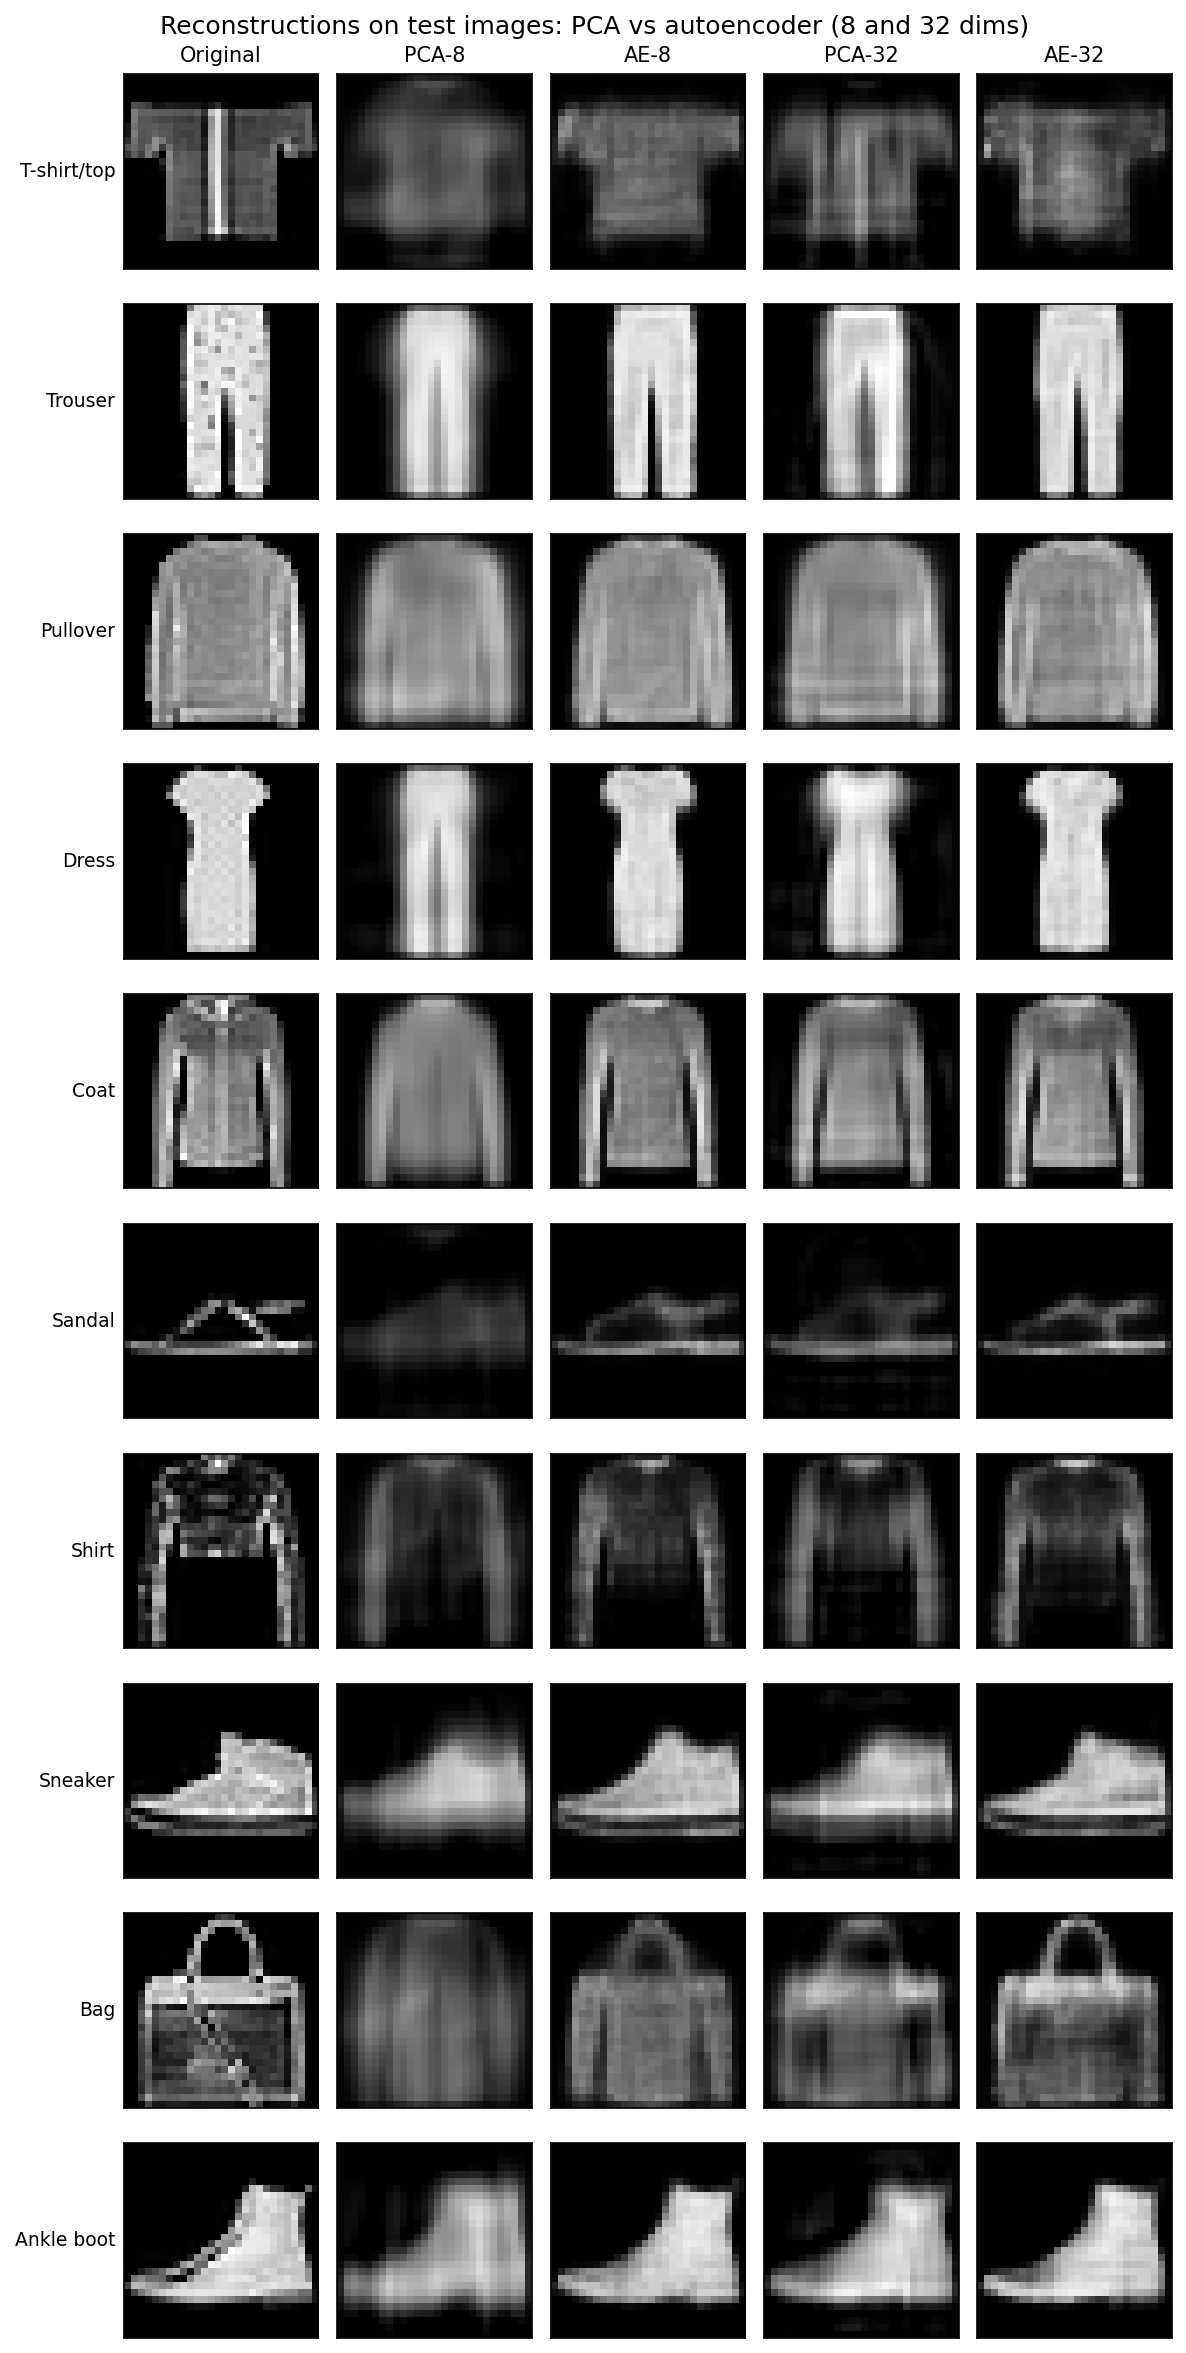

09_accuracy_vs_dim.png


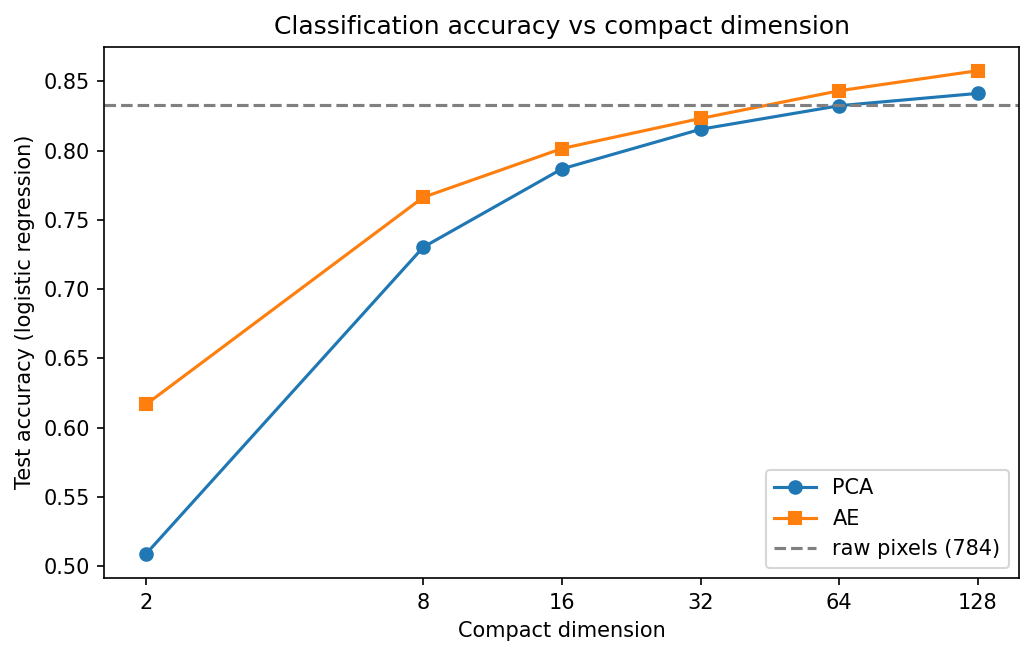

12_precision_vs_dim.png


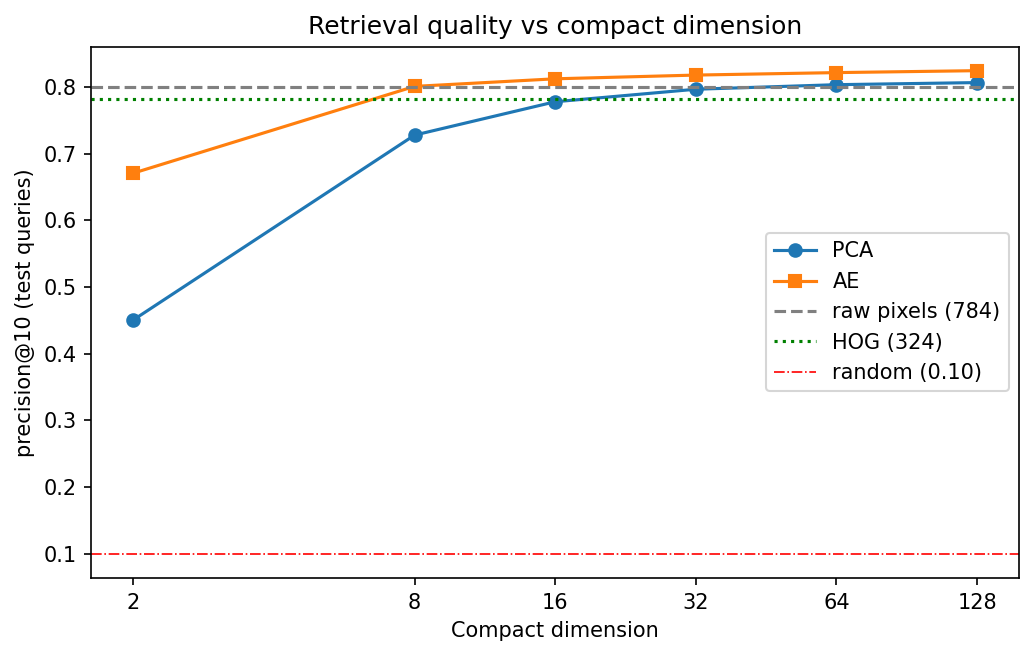

retrieval_panels/02_Pullover.png


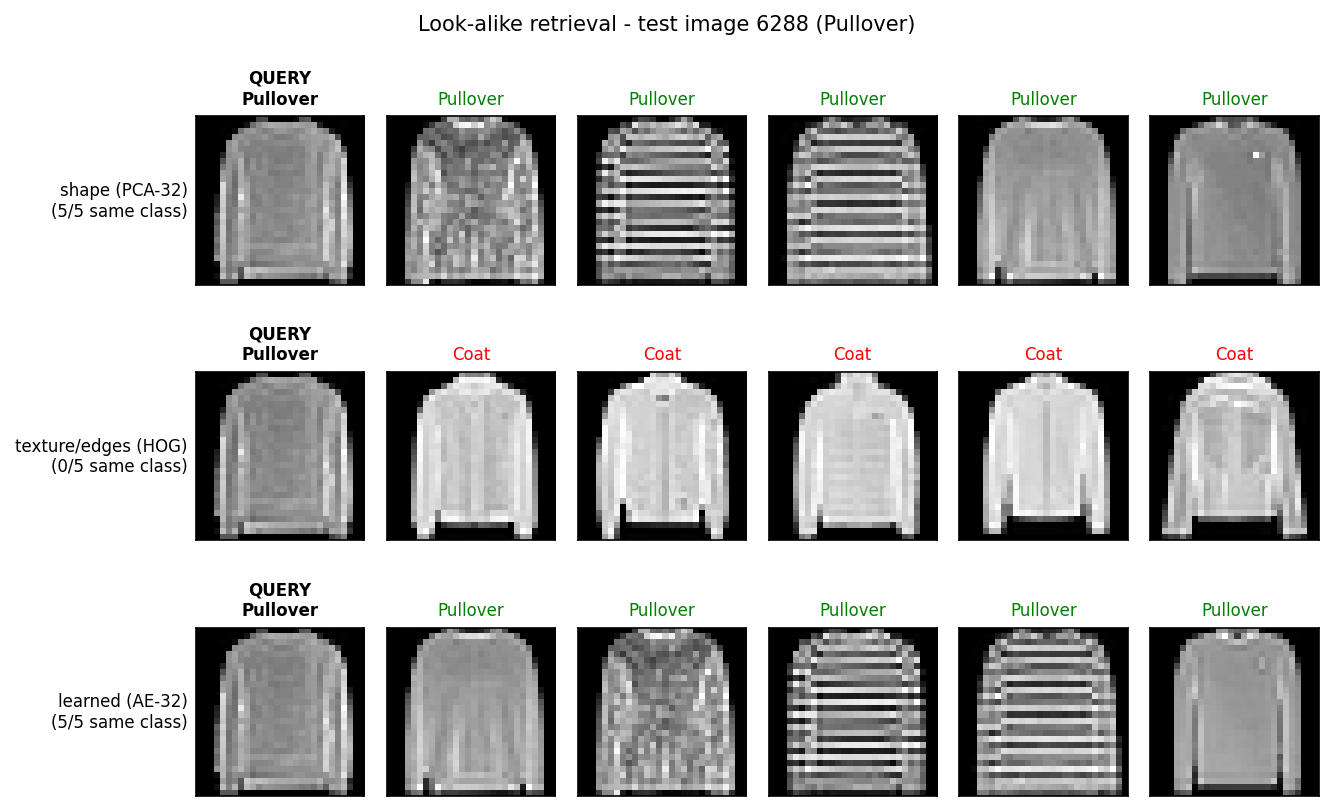

retrieval_panels/color_Handbags.png


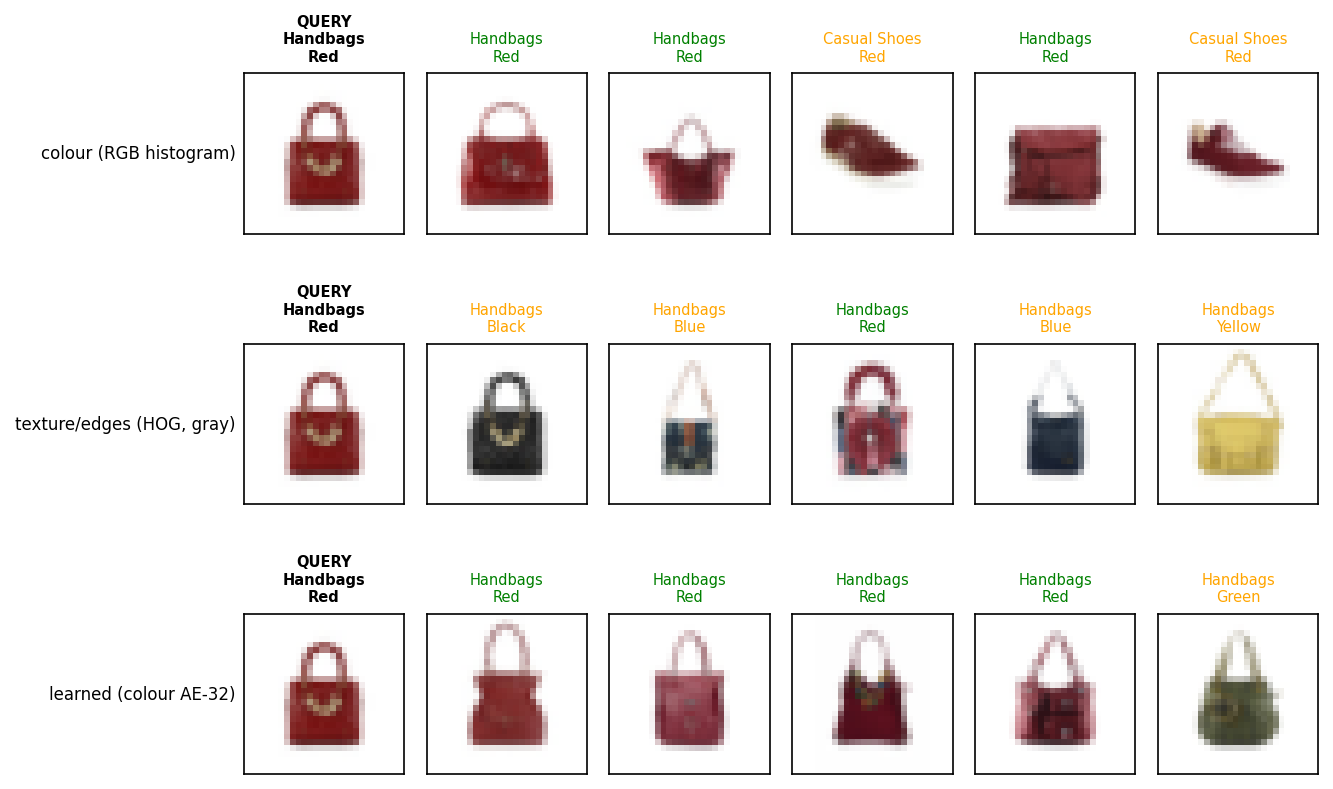

16_classification_vs_retrieval_zoom.png


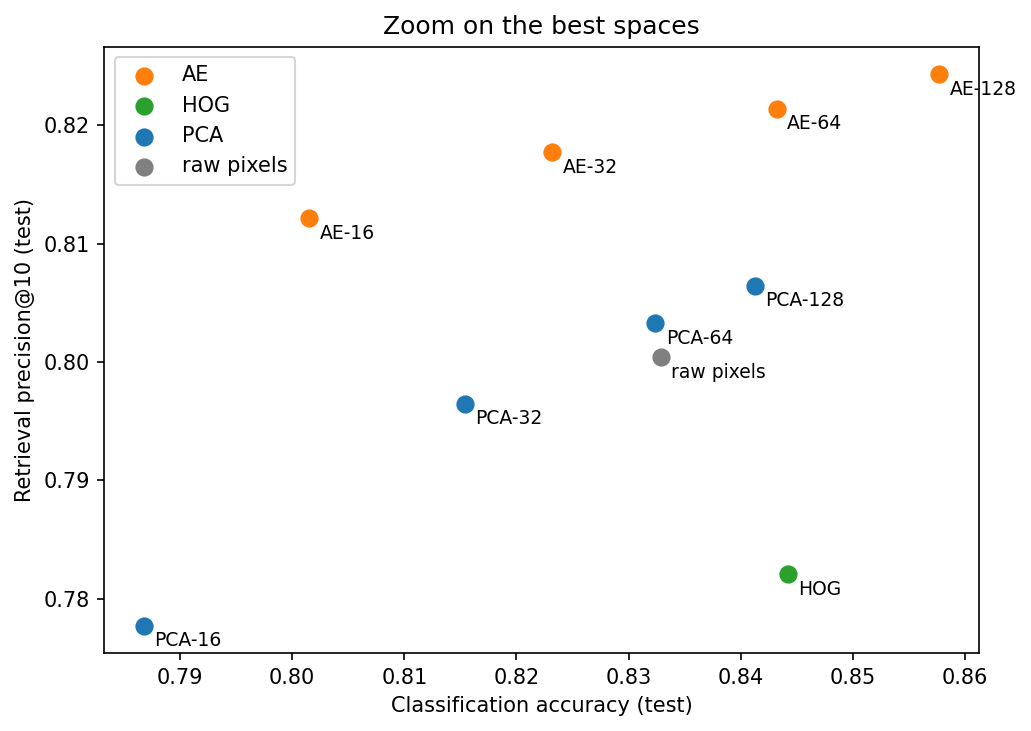

In [5]:
# 5) Figuras principais
figures = [
    "08_reconstruction_by_class.png",
    "09_accuracy_vs_dim.png",
    "12_precision_vs_dim.png",
    "retrieval_panels/02_Pullover.png",
    "retrieval_panels/color_Handbags.png",
    "16_classification_vs_retrieval_zoom.png",
]
for f in figures:
    print(f)
    display(Image(f"results/figures/{f}", width=650))